In [40]:
# Quick Test code cell to check if GPU is available and TensorFlow is installed correctly.
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

# Allocate GPU memory as needed instead of reserving most of it at startup.
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow:", tf.__version__)
print("GPUs detected:", gpus)
assert gpus, "No GPU detected: check your remote kernel and contact the server owner."

TensorFlow: 2.17.0
GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [46]:
# Team members: Luke Scanlon (23390573), Colin Walsh (23363185), Evelyn Sadlier (23367989)
# Full notebook execution: Full Notebook executes without errors.
# Reused implementation sources: 
#   ResNet Optimisation for Image Classification Repo: https://github.com/kiritgpillai/Resnet-Optimization-for-Image-Classification.git
#   Helped with optimising the ResNet architecture.

#   Building ResNet-20 from scratch Repo: https://github.com/tinayiluo0322/Building-ResNet20-For-CIFAR-10-From-Scratch.git

from pathlib import Path
#   Used to structure and build the ResNet architecture.

# The notebook is in Model, so the dataset is one folder above it.
data_dir = Path("/shared-datasets/Dataset_32x32")
train_dir = data_dir / "Training"
test_dir = data_dir / "Test"

# Stop with a clear message if either dataset folder is missing.
assert train_dir.is_dir(), f"Training folder missing: {train_dir}"
assert test_dir.is_dir(), f"Test folder missing: {test_dir}"

# Class names come from the subfolders in each dataset.
class_names = sorted(p.name for p in train_dir.iterdir() if p.is_dir())
test_classes = sorted(p.name for p in test_dir.iterdir() if p.is_dir())

# Ignore capitalisation to account for BlackBerry / Blackberry.
train_labels = {name.casefold() for name in class_names}
test_labels = {name.casefold() for name in test_classes}

assert train_labels == test_labels, "Training and test classes differ."

# Count image files rather than folders or other files.
image_extensions = {".jpg", ".jpeg", ".png"}

def count_images(folder):
    return sum(
        p.is_file() and p.suffix.lower() in image_extensions
        for p in folder.rglob("*")
    )

print("Number of classes:", len(class_names))
print("Training images:", count_images(train_dir))
print("Test images:", count_images(test_dir))
print("Classes match when capitalisation is ignored:", train_labels == test_labels)

Number of classes: 274
Training images: 147416
Test images: 49106
Classes match when capitalisation is ignored: True


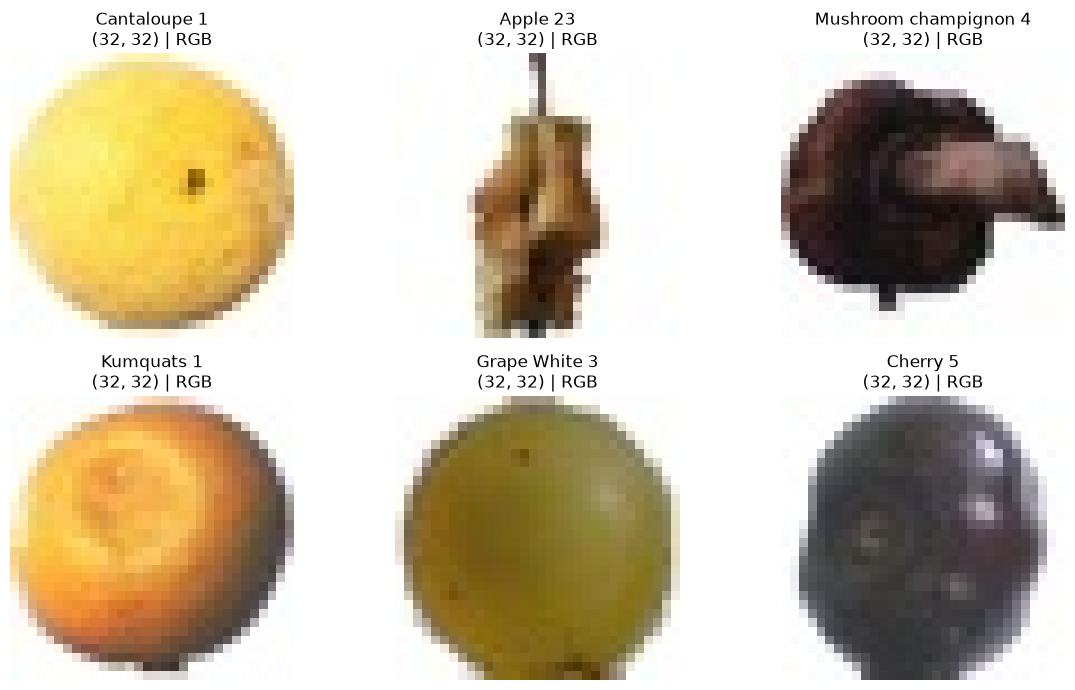

In [33]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# A fixed seed makes the selection repeatable.
rng = random.Random(42)
sample_classes = rng.sample(class_names, 6)

# Arrange six examples in two rows.
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, class_name in zip(axes.flat, sample_classes):
    # Choose one image from this class.
    image_files = sorted(
        p for p in (train_dir / class_name).iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )
    image_path = rng.choice(image_files)

    # Display the image with its dimensions and colour mode.
    with Image.open(image_path) as image:
        ax.imshow(image)
        ax.set_title(f"{class_name}\n{image.size} | {image.mode}")
        ax.axis("off")

plt.tight_layout()
plt.show()

1. Create a reproducible 80/20 training–validation split and consistent labels.

In [47]:
import random
import tensorflow as tf

# Report: Training Configuration / Hyperparameters: process 32 images per batch.
BATCH_SIZE = 32
# Report: Training Configuration / Hyperparameters: fixed seed for repeatable splits.
SEED = 42
# Report: Pre-Processing to the Data: reserve ~20% per class for validation.
VALIDATION_SPLIT = 0.2

extensions = {".jpg", ".jpeg", ".png"}
class_to_index = {
    name.casefold(): index
    for index, name in enumerate(class_names)
}

# Handle naming differences such as BlackBerry / Blackberry.
test_folders = {
    folder.name.casefold(): folder
    for folder in test_dir.iterdir()
    if folder.is_dir()
}

assert len(class_to_index) == len(class_names), "Duplicate class names."
assert len(test_folders) == len(class_names)
assert set(test_folders) == set(class_to_index), "Classes do not match."

def get_image_paths(folder):
    return sorted(
        str(path)
        for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in extensions
    )

train_paths, train_labels = [], []
val_paths, val_labels = [], []
test_paths, test_labels = [], []

rng = random.Random(SEED)

for class_name in class_names:
    # Report: Pre-Processing to the Data: map class names to integer labels.
    label = class_to_index[class_name.casefold()]
    paths = get_image_paths(train_dir / class_name)

    assert len(paths) >= 2, f"Too few training images: {class_name}"
    
    # Report: Pre-Processing to the Data: shuffle each class before its validation split.
    rng.shuffle(paths)
    n_val = max(1, min(len(paths) - 1,
                       int(len(paths) * VALIDATION_SPLIT)))

    val_paths.extend(paths[:n_val])
    val_labels.extend([label] * n_val)

    train_paths.extend(paths[n_val:])
    train_labels.extend([label] * (len(paths) - n_val))

    paths = get_image_paths(test_folders[class_name.casefold()])
    assert paths, f"No test images: {class_name}"

    test_paths.extend(paths)
    test_labels.extend([label] * len(paths))

assert set(train_paths).isdisjoint(val_paths)
# Report: Pre-Processing to the Data: keep test images out of development.
assert set(train_paths + val_paths).isdisjoint(test_paths)

for labels in (train_labels, val_labels, test_labels):
    assert set(labels) == set(range(len(class_names)))

print("Classes:", len(class_names))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))

Classes: 274
Training images: 118025
Validation images: 29391
Test images: 49106


2. Decode, normalise and batch the images. Only training data is shuffled.

In [48]:
def load_image(path, label):
    image = tf.io.decode_image(
        tf.io.read_file(path),
        channels=3,
        expand_animations=False,
    )

    # Check the original size instead of silently resizing.
    # Report: Pre-Processing to the Data: verify 32×32×3 RGB input (resizing is not done here).
    tf.debugging.assert_equal(
        tf.shape(image),
        [32, 32, 3],
        message="Expected a 32×32 RGB image",
    )
    image = tf.ensure_shape(image, (32, 32, 3))

    # Convert uint8 [0, 255] to float32 [0, 1].
    # Report: Pre-Processing to the Data: scale pixel intensities from [0,255] to [0,1].
    image = tf.image.convert_image_dtype(image, tf.float32)

    return image, label


def make_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((
        tf.constant(paths, dtype=tf.string),
        tf.constant(labels, dtype=tf.int32),
    ))

    if training:
        # Report: Pre-Processing to the Data: shuffle training images only.
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    return (
        dataset
        # Report: Pre-Processing to the Data: batch images using the configured batch size.
        .batch(BATCH_SIZE, drop_remainder=False)
        .prefetch(tf.data.AUTOTUNE)
    )


train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

3. Verify dimensions, labels, normalisation and batch counts. This scans every image, so it may take a little time.

In [36]:
import math

def verify_dataset(name, dataset, expected_images):
    expected_batches = math.ceil(expected_images / BATCH_SIZE)
    assert int(dataset.cardinality().numpy()) == expected_batches

    image_count = 0

    for batch_index, (images, labels) in enumerate(dataset):
        expected_size = min(
            BATCH_SIZE,
            expected_images - batch_index * BATCH_SIZE,
        )

        tf.debugging.assert_type(images, tf.float32)
        tf.debugging.assert_type(labels, tf.int32)

        tf.debugging.assert_equal(
            tf.shape(images), [expected_size, 32, 32, 3]
        )
        tf.debugging.assert_equal(tf.shape(labels), [expected_size])

        tf.debugging.assert_all_finite(images, "Invalid pixel values")
        tf.debugging.assert_greater_equal(images, 0.0)
        tf.debugging.assert_less_equal(images, 1.0)

        tf.debugging.assert_greater_equal(labels, 0)
        tf.debugging.assert_less(labels, len(class_names))

        image_count += int(tf.shape(images)[0].numpy())

    assert image_count == expected_images

    print(
        f"{name}: verified {image_count:,} images "
        f"across {expected_batches:,} batches"
    )


verify_dataset("Training", train_ds, len(train_paths))
verify_dataset("Validation", val_ds, len(val_paths))
verify_dataset("Test", test_ds, len(test_paths))

images, labels = next(iter(val_ds))

print("\nImage batch:", images.shape, images.dtype)
print("Label batch:", labels.shape, labels.dtype)
print("Example classes:", [
    class_names[int(label)] for label in labels[:5].numpy()
])

Training: verified 118,025 images across 3,689 batches
Validation: verified 29,391 images across 919 batches
Test: verified 49,106 images across 1,535 batches

Image batch: (32, 32, 32, 3) <dtype: 'float32'>
Label batch: (32,) <dtype: 'int32'>
Example classes: ['Almonds 1', 'Almonds 1', 'Almonds 1', 'Almonds 1', 'Almonds 1']


4. Define residual blocks using convolutional layers, batch normalisation and skip connections.

In [ ]:

from tensorflow.keras import layers, Model

def residual_block(x, filters, stride=1):
    # Report: Residual Learning: preserve the original input for the shortcut path.
    shortcut = x

    # Report: Residual Learning / Weight Initialisation: first 3×3 convolution with He Normal weights.
    y = layers.Conv2D(
        filters, kernel_size=3, strides=stride,
        padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(x)

    # Report: Batch Normalisation: normalise features before the first ReLU.
    y = layers.BatchNormalization()(y)
    # Report: Activation Function: apply ReLU to introduce non-linearity.
    y = layers.ReLU()(y)

    y = layers.Conv2D(
        filters, kernel_size=3, strides=1,
        padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(y)

    y = layers.BatchNormalization()(y)

    # Report: Residual Learning: use projection when dimensions or channel counts differ.
    if stride != 1 or x.shape[-1] != filters:
        # Report: Residual Learning: project shortcut using a 1×1 convolution.
        shortcut = layers.Conv2D(
            filters, kernel_size=1, strides=stride,
            padding="same", use_bias=False,
            kernel_initializer="he_normal"
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    # Report: Residual Learning: combine F(x) with the shortcut: H(x) = F(x) + x (identity case).
    y = layers.Add()([y, shortcut])

    # Report: Activation Function: activate after residual addition.
    return layers.ReLU()(y)


5. Build a ResNet-20 architecture for 32×32 RGB images with 274 output classes.


In [ ]:
NUM_CLASSES = len(class_names)

assert NUM_CLASSES == 274, (
    f"Expected 274 classes, found {NUM_CLASSES}"
)

def build_resnet(input_shape=(32, 32, 3), num_classes=274):
    # Report: Network Structure and Hyperparameters: input is 32×32 RGB.
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv2D(
        16, kernel_size=3, strides=1,
        padding="same", use_bias=False,
        kernel_initializer="he_normal"
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Report: Residual Learning: first stage: three blocks with 16 filters.
    for _ in range(3):
        x = residual_block(x, filters=16)

    # Report: Residual Learning: second stage begins with downsampling to 32 filters.
    x = residual_block(x, filters=32, stride=2)
    for _ in range(2):
        x = residual_block(x, filters=32)

    # Report: Residual Learning: third stage begins with downsampling to 64 filters.
    x = residual_block(x, filters=64, stride=2)
    for _ in range(2):
        x = residual_block(x, filters=64)
        
    # Report: Global Average Pooling: average each final feature map into one value.
    x = layers.GlobalAveragePooling2D()(x)

    # Report: Activation Function / Global Average Pooling: Softmax predicts 274 class probabilities.
    outputs = layers.Dense(
        num_classes, activation="softmax"
    )(x)

    return Model(
        inputs=inputs,
        outputs=outputs,
        name="ResNet20_Fruits"
    )

model = build_resnet(
    input_shape=(32, 32, 3),
    num_classes=NUM_CLASSES
)

model.summary()

Model: "ResNet20_Fruits"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_42 (Conv2D)  │ (None, 32, 32,    │        432 │ input_layer_2[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_42[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_38 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_43 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_38[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_43[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_39 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_44 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_39[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_44[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_18 (Add)        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │ re_lu_38[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_40 (ReLU)     │ (None, 32, 32,    │          0 │ add_18[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_45 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_40[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_45[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_41 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_46 (Conv2D)  │ (None, 32, 32,    │      2,304 │ re_lu_41[0][0]    │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_46[0][0]   │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_19 (Add)        │ (None, 32, 32,    │          0 │ batch_normalizat

 Total params: 291,202 (1.11 MB)

 Trainable params: 289,634 (1.10 MB)

 Non-trainable params: 1,568 (6.12 KB)

In [39]:
images, labels = next(iter(val_ds))

predictions = model(images, training=False)

print("Input shape:", images.shape)
print("Predictions shape:", predictions.shape)
print("Predicted classes:", tf.argmax(predictions, axis=1).numpy()[:5])
print("Actual classes:", labels.numpy()[:5])

Input shape: (32, 32, 32, 3)
Predictions shape: (32, 274)
Predicted classes: [187 187 187 187 187]
Actual classes: [0 0 0 0 0]



6. Compile the ResNet model and verify its architecture, input dimensions and output predictions.

In [ ]:
model.compile(
    # Report: Optimiser: use Adam to adjust network weights.
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    # Report: Loss Function: cross-entropy suits integer labels for mutually exclusive classes.
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

assert model.input_shape == (None, 32, 32, 3)

assert model.output_shape == (None, NUM_CLASSES)

residual_additions = [
    layer for layer in model.layers
    if isinstance(layer, layers.Add)
]

# Report: Residual Learning: verify that the architecture has nine residual blocks.
assert len(residual_additions) == 9, (
    f"Expected 9 residual blocks, got {len(residual_additions)}"
)

images, labels = next(iter(val_ds))
predictions = model(images, training=False)

assert predictions.shape == (images.shape[0], NUM_CLASSES)
tf.debugging.assert_all_finite(
    predictions, "Predictions contain invalid values"
)

tf.debugging.assert_near(
    tf.reduce_sum(predictions, axis=1),
    tf.ones((images.shape[0],)),
    atol=1e-5
)

print("Model compiled successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Residual blocks:", len(residual_additions))
print("Prediction batch shape:", predictions.shape)
print("CNN005 architecture verification passed.")

Model compiled successfully.
Input shape: (None, 32, 32, 3)
Output shape: (None, 274)
Residual blocks: 9
Prediction batch shape: (32, 274)
CNN005 architecture verification passed.


## 7. Configure Training Parameters

Set the epoch count, batch size, learning rate and optimiser. Prepare the data loaders and compile a fresh ResNet model for training on Hades.

In [ ]:
# CNN006: Configure training
# Report: Training Configuration / Hyperparameters: baseline runs for 30 epochs.
EPOCHS = 30
# Report: Training Configuration / Hyperparameters: 32 images per batch.
BATCH_SIZE = 32
# Report: Training Configuration / Hyperparameters: Adam learning rate of 0.001.
LEARNING_RATE = 0.001

# Report: Training Configuration: seed the training run for reproducibility.
tf.keras.utils.set_random_seed(SEED)

assert tf.config.list_physical_devices("GPU"), (
    "Select your Hades GPU kernel before training."
)

# Rebuild the loaders using the configured batch size.
train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)

# Start with a fresh model.
# Report: Training Configuration: initialise a fresh baseline ResNet-20.
model = build_resnet(
    input_shape=(32, 32, 3),
    num_classes=len(class_names),
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

print(f"Epochs: {EPOCHS}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Optimiser: Adam | Learning rate: {LEARNING_RATE}")

Epochs: 30
Batch size: 32
Optimiser: Adam | Learning rate: 0.001


## 8. Train the Model and Save Results

Train ResNet using the prepared training and validation datasets on Hades.
Save the checkpoint with the lowest validation loss and the final model.
Record training settings, elapsed time, and training/validation accuracy and
loss. The test dataset remains reserved for final evaluation.

In [44]:
import json
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter

assert tf.config.list_physical_devices("GPU"), "Connect to the Hades GPU kernel."

# Give each run its own folder on the server.
run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
run_dir = Path("training_runs") / run_id
run_dir.mkdir(parents=True, exist_ok=False)

def save_json(filename, data):
    (run_dir / filename).write_text(
        json.dumps(data, indent=2),
        encoding="utf-8",
    )

# Record the configuration before training starts.
save_json("config.json", {
    "model": model.name,
    "epochs_requested": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "optimizer": tf.keras.optimizers.serialize(model.optimizer),
    "loss": "SparseCategoricalCrossentropy",
    "seed": SEED,
    "training_images": len(train_paths),
    "validation_images": len(val_paths),
    "tensorflow_version": tf.__version__,
    "checkpoint_monitor": "val_loss",
})

save_json("class_names.json", class_names)

callbacks = [
    # Report: Training Configuration / Regularisation: save the checkpoint with minimum validation loss.
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(run_dir / "best_model.keras"),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    # Save completed epochs even if training is interrupted later.
    tf.keras.callbacks.CSVLogger(str(run_dir / "history.csv")),
]

print("Saving results to:", run_dir.resolve())

start_time = perf_counter()

# Report: Training Configuration: train and log accuracy and loss across epochs.
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=2,
)

training_seconds = perf_counter() - start_time

# Save the final epoch's model separately from the best checkpoint.
# Report: Training Configuration: keep final-epoch model separate from best checkpoint.
model.save(str(run_dir / "final_model.keras"))

metrics = {
    name: [float(value) for value in values]
    for name, values in history.history.items()
}
save_json("history.json", metrics)

# Epoch numbers shown in the report start at 1.
# Report: Training Configuration: find the epoch with lowest validation loss.
best_index = min(
    range(len(metrics["val_loss"])),
    key=lambda index: metrics["val_loss"][index],
)

summary = {
    "epochs_completed": len(history.epoch),
    "training_seconds": training_seconds,
    "best_epoch": best_index + 1,
    "training_loss_at_best_epoch": metrics["loss"][best_index],
    "training_accuracy_at_best_epoch": metrics["accuracy"][best_index],
    "best_validation_loss": metrics["val_loss"][best_index],
    "validation_accuracy_at_best_epoch": metrics["val_accuracy"][best_index],
}
save_json("summary.json", summary)

print(f"\nTraining time: {training_seconds / 60:.2f} minutes")
print(f"Best epoch: {summary['best_epoch']}")
print(f"Validation loss: {summary['best_validation_loss']:.4f}")
print(f"Validation accuracy: {summary['validation_accuracy_at_best_epoch']:.2%}")
print("Saved files:", run_dir.resolve())

Saving results to: /workspace/training_runs/20261102_213030_672549
Epoch 1/30

Epoch 1: val_loss improved from inf to 0.01897, saving model to training_runs/20261102_213030_672549/best_model.keras
3689/3689 - 43s - 12ms/step - accuracy: 0.9964 - loss: 0.0117 - val_accuracy: 0.9935 - val_loss: 0.0190
Epoch 2/30

Epoch 2: val_loss improved from 0.01897 to 0.00711, saving model to training_runs/20261102_213030_672549/best_model.keras
3689/3689 - 28s - 8ms/step - accuracy: 0.9969 - loss: 0.0102 - val_accuracy: 0.9977 - val_loss: 0.0071
Epoch 3/30

Epoch 3: val_loss did not improve from 0.00711
3689/3689 - 28s - 8ms/step - accuracy: 0.9965 - loss: 0.0107 - val_accuracy: 0.9974 - val_loss: 0.0072
Epoch 4/30

Epoch 4: val_loss did not improve from 0.00711
3689/3689 - 28s - 8ms/step - accuracy: 0.9971 - loss: 0.0091 - val_accuracy: 0.9902 - val_loss: 0.0377
Epoch 5/30

Epoch 5: val_loss improved from 0.00711 to 0.00676, saving model to training_runs/20261102_213030_672549/best_model.keras
3689

## 9. Load the Best Model and Review Training Results

Load the checkpoint selected by the lowest validation loss and review
the recorded training results before evaluating on the test dataset.

In [43]:
# Load the best checkpoint instead of using the final epoch's weights.
# Report: Training Configuration: reload the checkpoint selected by validation loss.
model = tf.keras.models.load_model(
    str(run_dir / "best_model.keras")
)

summary = json.loads(
    (run_dir / "summary.json").read_text(encoding="utf-8")
)

print("Results folder:", run_dir.resolve())
print("Epochs completed:", summary["epochs_completed"])
print(f"Training time: {summary['training_seconds'] / 60:.2f} minutes")
print("Best epoch:", summary["best_epoch"])
print(f"Training loss: {summary['training_loss_at_best_epoch']:.4f}")
print(f"Training accuracy: {summary['training_accuracy_at_best_epoch']:.2%}")
print(f"Validation loss: {summary['best_validation_loss']:.4f}")
print(
    "Validation accuracy:",
    f"{summary['validation_accuracy_at_best_epoch']:.2%}"
)

Results folder: /workspace/training_runs/20261030_133948_938065
Epochs completed: 30
Training time: 14.18 minutes
Best epoch: 28
Training loss: 0.0111
Training accuracy: 99.65%
Validation loss: 0.0031
Validation accuracy: 99.92%


### Baseline Training Results

Run ID: `20261030_133948_938065`

| Metric | Result |
| --- | --- |
| Epochs completed | 30 |
| Training time | 14.18 minutes |
| Best epoch, selected by lowest validation loss | 28 |
| Training loss at best epoch | 0.0111 |
| Training accuracy at best epoch | 99.65% |
| Validation loss at best epoch | 0.0031 |
| Validation accuracy at best epoch | 99.92% |

Run artifacts: [training_runs/20261030_133948_938065/](training_runs/20261030_133948_938065/)

These are training and validation results. Final test evaluation is pending.

## 10. Prepare Stratified 3-Fold Cross-Validation

Combine the existing training and validation subsets to recover the original
training set. Divide it into three stratified folds, preserving class
proportions. Each fold will serve as validation data once, while the other
two folds provide training data.

The original test set remains separate. A fresh ResNet will be trained
for each fold using the same training settings.

In [ ]:
import numpy as np

# Report: Cross-Fold Validation: run stratified three-fold cross-validation.
N_FOLDS = 3

# Recover the original training set; exclude the test set.
# Report: Cross-Fold Validation: only original training images enter the folds.
cv_paths = np.asarray(train_paths + val_paths)
cv_labels = np.asarray(train_labels + val_labels, dtype=np.int32)

assert len(cv_paths) == len(cv_labels)
assert len(set(cv_paths.tolist())) == len(cv_paths)
assert set(cv_paths.tolist()).isdisjoint(test_paths)

classes, counts = np.unique(cv_labels, return_counts=True)
assert len(classes) == len(class_names)
assert counts.min() >= N_FOLDS

rng = np.random.default_rng(SEED)
validation_parts = [[] for _ in range(N_FOLDS)]
offset = 0

# Shuffle each class independently and distribute its images across folds.
# Rotate the starting fold to keep overall fold sizes balanced.
for label in classes:
    indices = np.flatnonzero(cv_labels == label)#
    # Report: Cross-Fold Validation: shuffle examples separately within each class.
    rng.shuffle(indices)

    # Report: Cross-Fold Validation: distribute each class across three validation folds.
    assignments = (np.arange(len(indices)) + offset) % N_FOLDS

    for fold in range(N_FOLDS):
        validation_parts[fold].append(indices[assignments == fold])

    offset = (offset + len(indices)) % N_FOLDS

all_indices = np.arange(len(cv_paths))
fold_splits = []
validation_uses = np.zeros(len(cv_paths), dtype=np.int32)

for fold, parts in enumerate(validation_parts, start=1):
    validation_indices = np.sort(np.concatenate(parts))

    # All remaining images form this fold's training subset.
    training_mask = np.ones(len(cv_paths), dtype=bool)
    # Report: Cross-Fold Validation: remove held-out fold from its training split.
    training_mask[validation_indices] = False
    training_indices = all_indices[training_mask]

    assert np.intersect1d(
        training_indices, validation_indices
    ).size == 0

    for indices in (training_indices, validation_indices):
        assert np.array_equal(np.unique(cv_labels[indices]), classes)

    fold_splits.append((training_indices, validation_indices))
    validation_uses[validation_indices] += 1

    print(
        f"Fold {fold}: "
        f"{len(training_indices):,} training images | "
        f"{len(validation_indices):,} validation images"
    )

# Report: Cross-Fold Validation: each image must be validated exactly once.
assert np.all(validation_uses == 1)

print(f"\nCross-validation images: {len(cv_paths):,}")
print(f"Classes: {len(classes)}")
print("Test set excluded. Fold checks passed.")

## 11. Train the Cross-Validation Models

Train a fresh ResNet-20 for each of the three folds using identical training
settings. Save each fold's best checkpoint, selected by lowest validation
loss, together with its final model, training history and results.

The original test set remains excluded.

In [ ]:
import json
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter

assert tf.config.list_physical_devices("GPU"), "Select the Hades GPU kernel."

cv_run_id = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
cv_run_dir = Path("cross_validation_runs") / cv_run_id
cv_run_dir.mkdir(parents=True, exist_ok=False)

def save_cv_json(path, data):
    path.write_text(json.dumps(data, indent=2), encoding="utf-8")

# Record settings shared by all folds.
save_cv_json(cv_run_dir / "config.json", {
    "folds": N_FOLDS,
    "epochs_requested": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "seed": SEED,
    "checkpoint_monitor": "val_loss",
    "tensorflow_version": tf.__version__,
    "cross_validation_images": len(cv_paths),
})

save_cv_json(cv_run_dir / "class_names.json", class_names)

fold_results = []

for fold, (training_indices, validation_indices) in enumerate(
    fold_splits, start=1
):
    print(f"\n========== FOLD {fold}/{N_FOLDS} ==========")

    fold_dir = cv_run_dir / f"fold_{fold}"
    fold_dir.mkdir()

    # Save the exact split so this fold can be reconstructed.
    np.savez_compressed(
        fold_dir / "split_paths.npz",
        training_paths=cv_paths[training_indices],
        validation_paths=cv_paths[validation_indices],
    )

    fold_train_ds = make_dataset(
        cv_paths[training_indices].tolist(),
        cv_labels[training_indices].tolist(),
        training=True,
    )
    fold_val_ds = make_dataset(
        cv_paths[validation_indices].tolist(),
        cv_labels[validation_indices].tolist(),
    )

    # Reset Keras state and initialise independent weights for this fold.
    # Report: Cross-Fold Validation: clear previous model state before each fold.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    # Report: Cross-Fold Validation: train a new ResNet-20 from freshly initialised weights.
    fold_model = build_resnet(
        input_shape=(32, 32, 3),
        num_classes=len(class_names),
    )
    fold_model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    fold_callbacks = [
        # Report: Cross-Fold Validation: select each fold checkpoint by minimum validation loss.
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(fold_dir / "best_model.keras"),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(str(fold_dir / "history.csv")),
    ]

    started = perf_counter()

    # Report: Cross-Fold Validation: train each fold with the same baseline settings.
    fold_history = fold_model.fit(
        fold_train_ds,
        validation_data=fold_val_ds,
        epochs=EPOCHS,
        callbacks=fold_callbacks,
        verbose=2,
    )

    training_seconds = perf_counter() - started
    fold_model.save(str(fold_dir / "final_model.keras"))

    metrics = {
        name: [float(value) for value in values]
        for name, values in fold_history.history.items()
    }
    save_cv_json(fold_dir / "history.json", metrics)

    # Select the same epoch as the best-checkpoint callback.
    # Report: Cross-Fold Validation / Results: identify the best validation-loss epoch.
    best_index = min(
        range(len(metrics["val_loss"])),
        key=lambda index: metrics["val_loss"][index],
    )

    result = {
        "fold": fold,
        "training_images": len(training_indices),
        "validation_images": len(validation_indices),
        "epochs_completed": len(fold_history.epoch),
        "training_seconds": training_seconds,
        "best_epoch": best_index + 1,
        "training_loss": metrics["loss"][best_index],
        "training_accuracy": metrics["accuracy"][best_index],
        "validation_loss": metrics["val_loss"][best_index],
        "validation_accuracy": metrics["val_accuracy"][best_index],
    }

    save_cv_json(fold_dir / "summary.json", result)
    fold_results.append(result)

    # Preserve completed fold results before starting the next fold.
    save_cv_json(cv_run_dir / "fold_results.json", fold_results)

    print(
        f"Fold {fold} complete | "
        f"Best epoch: {result['best_epoch']} | "
        f"Validation accuracy: {result['validation_accuracy']:.2%}"
    )

print("\nAll folds completed.")
print("Results folder:", cv_run_dir.resolve())

## 12. Summarise Cross-Validation Results

Compare validation accuracy and loss across the three folds.
Report their mean and sample standard deviation to describe variation
between folds. Each fold's metrics come from its selected best epoch.

In [21]:
assert len(fold_results) == N_FOLDS, (
    "Wait until all folds have finished."
)

# Report: Results and Evaluation / Cross-Validation results: collect fold accuracies.
accuracies = np.asarray([
    result["validation_accuracy"] for result in fold_results
])
losses = np.asarray([
    result["validation_loss"] for result in fold_results
])

cv_summary = {
    "folds_completed": len(fold_results),
    "mean_validation_accuracy": float(accuracies.mean()),
    "std_validation_accuracy": float(accuracies.std(ddof=1)),
    "mean_validation_loss": float(losses.mean()),
    "std_validation_loss": float(losses.std(ddof=1)),
    "total_training_seconds": sum(
        result["training_seconds"] for result in fold_results
    ),
}

save_cv_json(cv_run_dir / "cv_summary.json", cv_summary)

for result in fold_results:
    print(
        f"Fold {result['fold']} | "
        f"Best epoch: {result['best_epoch']} | "
        f"Validation accuracy: {result['validation_accuracy']:.2%} | "
        f"Validation loss: {result['validation_loss']:.4f}"
    )

print(
    "\nMean validation accuracy: "
    f"{accuracies.mean():.2%} "
    f"(sample SD: {accuracies.std(ddof=1) * 100:.2f} percentage points)"
)
print(
    f"Mean validation loss: {losses.mean():.4f} "
    f"(sample SD: {losses.std(ddof=1):.4f})"
)
print(
    "Total training time: "
    f"{cv_summary['total_training_seconds'] / 60:.2f} minutes"
)
print("Results folder:", cv_run_dir.resolve())

Fold 1 | Best epoch: 26 | Validation accuracy: 99.79% | Validation loss: 0.0073
Fold 2 | Best epoch: 24 | Validation accuracy: 99.85% | Validation loss: 0.0059
Fold 3 | Best epoch: 28 | Validation accuracy: 99.59% | Validation loss: 0.0128

Mean validation accuracy: 99.74% (sample SD: 0.13 percentage points)
Mean validation loss: 0.0087 (sample SD: 0.0036)
Total training time: 38.59 minutes
Results folder: /workspace/cross_validation_runs/20261030_150350_149048


13. Final Test Evaluation

In [49]:
from pathlib import Path

# Existing completed run on the server.
cv_run_dir = Path("cross_validation_runs/20261030_150350_149048")
assert (cv_run_dir / "fold_2/best_model.keras").is_file(), "Check the saved model path."

In [56]:
import numpy as np
import tensorflow as tf

# Load fold 2's saved checkpoint.
# Report: Results and Evaluation: evaluate the saved fold-2 checkpoint on held-out test data.
eval_model = tf.keras.models.load_model(
    cv_run_dir / "fold_2" / "best_model.keras",
    compile=False,
)

# Apply the existing preprocessing without shuffling.
eval_ds = make_dataset(test_paths, test_labels)

# Get predicted and actual test labels.
# Report: Results and Evaluation: convert Softmax predictions to class labels.
y_pred = eval_model.predict(eval_ds, verbose=1).argmax(axis=1)
y_true = np.asarray(test_labels)

# Count actual/predicted class pairs in a confusion matrix.
n_classes = eval_model.output_shape[-1]
cm = np.zeros((n_classes, n_classes), dtype=np.int64)
# Report: Results and Evaluation: build the confusion matrix for per-class analysis.
np.add.at(cm, (y_true, y_pred), 1)

# Calculate precision and recall for each class; undefined scores become zero.
tp = cm.diagonal()
precision = np.divide(
    tp, cm.sum(axis=0),
    out=np.zeros(n_classes), where=cm.sum(axis=0) != 0,
)
recall = np.divide(
    tp, cm.sum(axis=1),
    out=np.zeros(n_classes), where=cm.sum(axis=1) != 0,
)

# Calculate each class's F1-score before taking the macro average.
f1 = np.divide(
    2 * precision * recall, precision + recall,
    out=np.zeros(n_classes), where=(precision + recall) != 0,
)

# Macro averages give every class equal weight.
print(f"Final test accuracy: {np.mean(y_true == y_pred):.2%}")
print(f"Macro precision:     {precision.mean():.4f}")
print(f"Macro recall:        {recall.mean():.4f}")
print(f"Macro F1-score:      {f1.mean():.4f}")

1535/1535 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
Final test accuracy: 98.49%
Macro precision:     0.9864
Macro recall:        0.9840
Macro F1-score:      0.9831


14. Training and Validation Curves

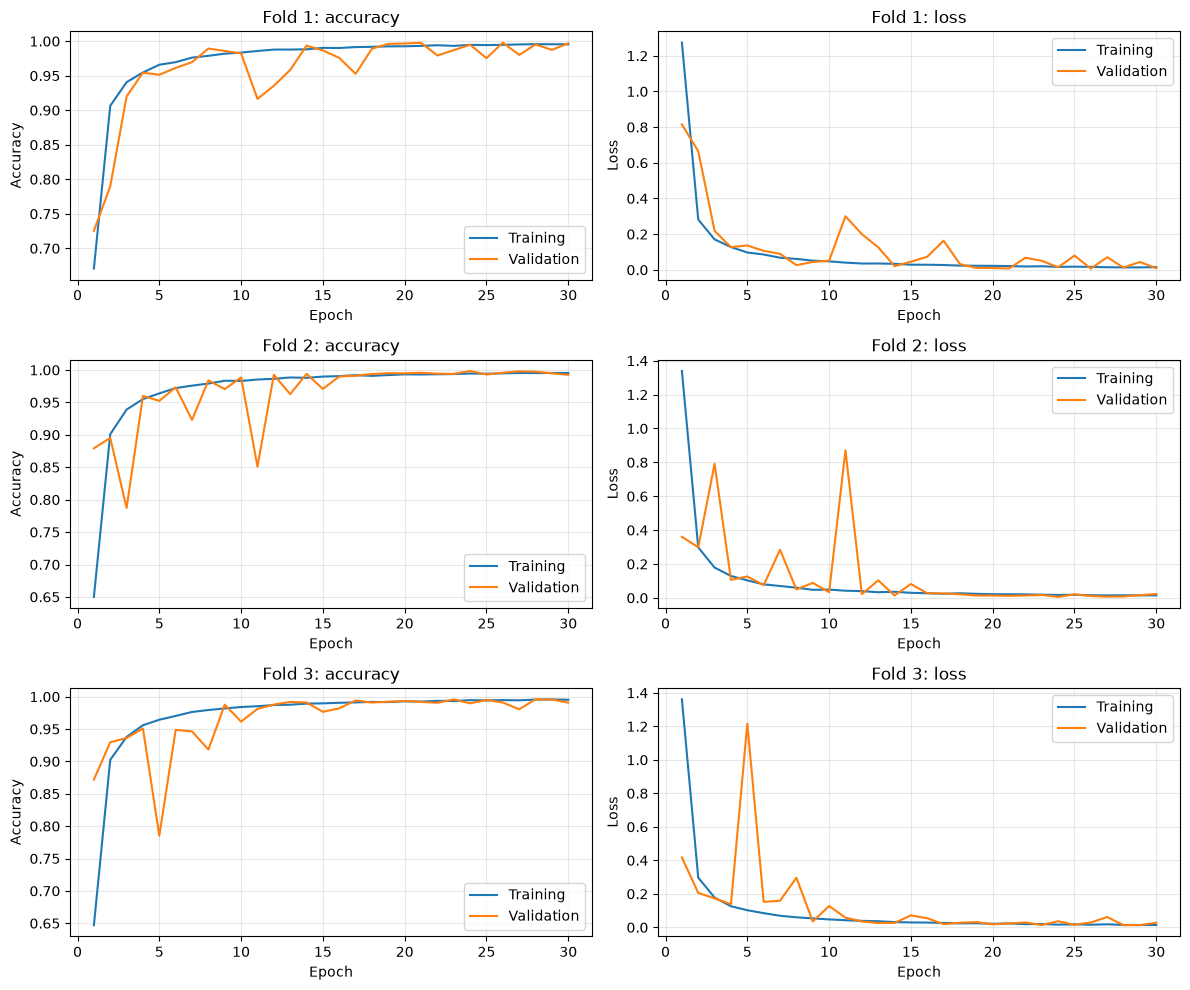

In [57]:
import json
import matplotlib.pyplot as plt

# Plot the saved training histories for all three folds.
# Report: Results and Evaluation: plot training and validation curves for each fold.
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
histories = []

for row, fold in enumerate((1, 2, 3)):
    # Read this fold's saved results without retraining.
    history = json.loads(
        (cv_run_dir / f"fold_{fold}" / "history.json").read_text()
    )
    histories.append(history)
    epochs = np.arange(1, len(history["loss"]) + 1)

    # Plot training and validation values for each metric.
    for column, metric in enumerate(("accuracy", "loss")):
        ax = axes[row, column]
        ax.plot(epochs, history[metric], label="Training")
        ax.plot(epochs, history[f"val_{metric}"], label="Validation")
        ax.set(
            title=f"Fold {fold}: {metric}",
            xlabel="Epoch",
            ylabel=metric.capitalize(),
        )
        ax.legend()
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

15. Confusion Matrix, Classification Report and Results Analysis

 ID  Class                                  Precision    Recall        F1  Support
  0  Almonds 1                                 1.0000    1.0000    1.0000       77
  1  Apple 10                                  1.0000    1.0000    1.0000      231
  2  Apple 11                                  1.0000    1.0000    1.0000      142
  3  Apple 12                                  1.0000    1.0000    1.0000      154
  4  Apple 13                                  1.0000    1.0000    1.0000      235
  5  Apple 14                                  0.9747    1.0000    0.9872      154
  6  Apple 17                                  0.9950    1.0000    0.9975      201
  7  Apple 18                                  1.0000    0.9958    0.9979      240
  8  Apple 19                                  1.0000    1.0000    1.0000      241
  9  Apple 20                                  1.0000    1.0000    1.0000      234
 10  Apple 21                                  0.9701    1.0000    0.9848      162
 11 

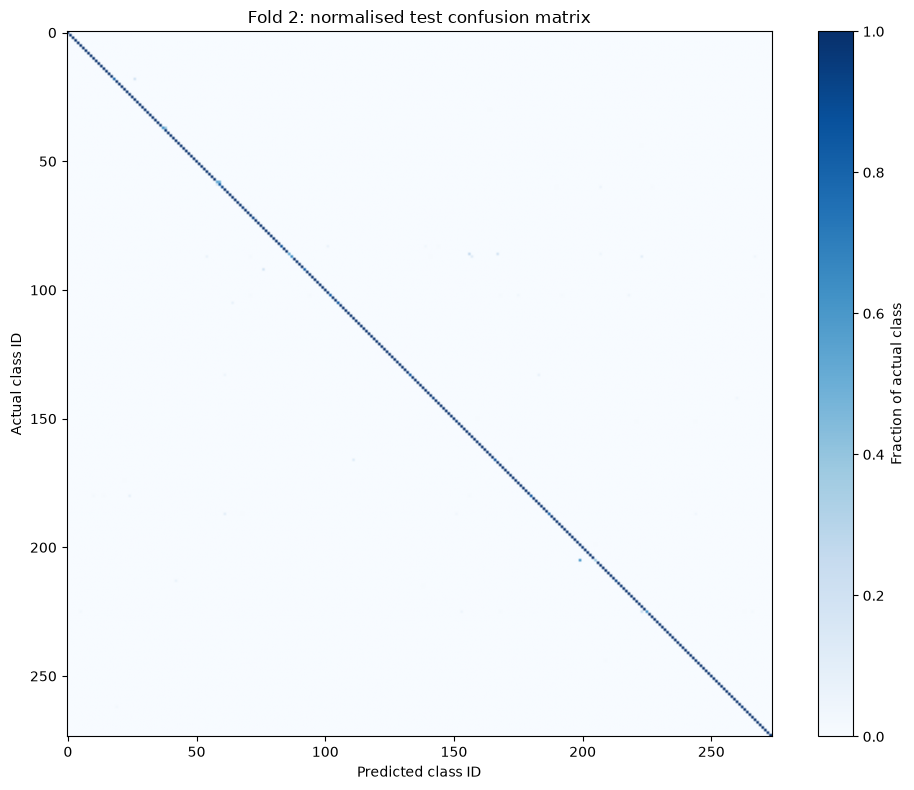


LOWEST CLASS F1-SCORES
Pepper Yellow 1: precision=0.9885, recall=0.3874, F1=0.5566, support=222
Cantaloupe 2: precision=0.7909, recall=0.5305, F1=0.6350, support=164
Banana 2: precision=0.5414, recall=0.9730, F1=0.6957, support=74
Corn 1: precision=1.0000, recall=0.5400, F1=0.7013, support=150
Cantaloupe 3: precision=0.6333, recall=0.8526, F1=0.7268, support=156

MOST COMMON CONFUSIONS
Pepper Yellow 1 -> Pepper Orange 2: 136 images (61.26% of actual class)
Cantaloupe 2 -> Cantaloupe 3: 77 images (46.95% of actual class)
Banana 1 -> Banana 2: 61 images (36.75% of actual class)
Corn 1 -> Onion White 1: 37 images (24.67% of actual class)
Potato Sweet 1 -> Potato Red 1: 35 images (23.33% of actual class)

TRAINING ANALYSIS
Fold 1: minimum validation loss 0.0073 at epoch 26; final validation loss 0.0094.
Fold 2: minimum validation loss 0.0059 at epoch 24; final validation loss 0.0226.
Fold 3: minimum validation loss 0.0128 at epoch 28; final validation loss 0.0279.

Low recall means the mo

In [58]:
# Use the original class order saved with the models.
names = json.loads((cv_run_dir / "class_names.json").read_text())
support = cm.sum(axis=1)

# Print per-class metrics; support is the number of actual test images.
print(f"{'ID':>3}  {'Class':38} {'Precision':>9} {'Recall':>9} {'F1':>9} {'Support':>8}")
for i, name in enumerate(names):
    print(
        f"{i:3}  {name:38} {precision[i]:9.4f} "
        f"{recall[i]:9.4f} {f1[i]:9.4f} {support[i]:8}"
    )

# Include overall accuracy and macro averages in the report.
print(f"\nTest accuracy:   {np.mean(y_true == y_pred):.2%}")
print(f"Macro precision: {precision.mean():.4f}")
print(f"Macro recall:    {recall.mean():.4f}")
print(f"Macro F1-score:  {f1.mean():.4f}")

# Normalise each row to show the fraction of each actual class.
normalised_cm = np.divide(
    cm, support[:, None],
    out=np.zeros_like(cm, dtype=float),
    where=support[:, None] != 0,
)

# Class IDs correspond to the classification report above.
plt.figure(figsize=(10, 8))
plt.imshow(normalised_cm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Fraction of actual class")
plt.xlabel("Predicted class ID")
plt.ylabel("Actual class ID")
plt.title("Fold 2: normalised test confusion matrix")
plt.tight_layout()
plt.show()

# Identify the five classes with the lowest F1-scores.
weakest = np.argsort(f1)[:5]
print("\nLOWEST CLASS F1-SCORES")
for i in weakest:
    print(
        f"{names[i]}: precision={precision[i]:.4f}, "
        f"recall={recall[i]:.4f}, F1={f1[i]:.4f}, "
        f"support={support[i]}"
    )

# Exclude correct predictions, then rank the largest confusion counts.
errors = cm.copy()
np.fill_diagonal(errors, 0)
pairs = np.argsort(errors.ravel())[::-1][:5]

print("\nMOST COMMON CONFUSIONS")
for position in pairs:
    actual, predicted = np.unravel_index(position, errors.shape)
    count = errors[actual, predicted]
    if count > 0:
        print(
            f"{names[actual]} -> {names[predicted]}: "
            f"{count} images ({count / support[actual]:.2%} of actual class)"
        )

# Compare selected and final validation losses to help interpret the curves.
print("\nTRAINING ANALYSIS")
for fold, history in enumerate(histories, start=1):
    best = int(np.argmin(history["val_loss"]))
    print(
        f"Fold {fold}: minimum validation loss "
        f"{history['val_loss'][best]:.4f} at epoch {best + 1}; "
        f"final validation loss {history['val_loss'][-1]:.4f}."
    )

# Explain what the outputs indicate and suggest follow-up experiments.
print("""
Low recall means the model misses examples of that class.
Low precision means other classes are incorrectly assigned that label.
Inspect the largest confusion pairs for similar colours, shapes or textures.

Sustained rising validation loss alongside falling training loss suggests
overfitting; isolated spikes may indicate training instability.

Potential improvements:
- Test higher-resolution inputs to preserve fine details between similar classes.
- Add training-only augmentation for lighting, rotation and background variation.
- Investigate learning-rate scheduling or early stopping where validation worsens.

Limitations:
Image-level cross-validation may place related views in different folds.
Controlled backgrounds may also limit generalisation to real-world photographs.
Use validation data to assess improvements; reserve a fresh holdout for final
evaluation if these test results guide further model development.
""")